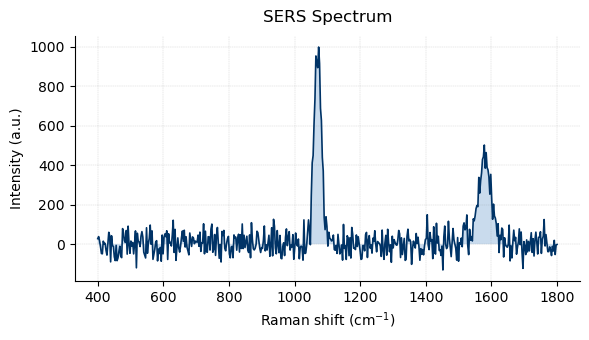

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# -----------------------------
# 1. 模拟数据（可替换成你自己的）
# -----------------------------
raman_shift = np.linspace(400, 1800, 500)               # 横轴：拉曼位移 (cm⁻¹)
intensity   = (
        1000 * np.exp(-((raman_shift - 1070) / 15) ** 2)   # 主 1070 cm⁻¹ 峰
      + 450  * np.exp(-((raman_shift - 1580) / 25) ** 2)   # 次 1580 cm⁻¹ 峰
      + 50   * np.random.randn(500)                        # 噪声
)

# -----------------------------
# 2. 画图
# -----------------------------
fig, ax = plt.subplots(figsize=(6, 3.5))

# 2.1 选用蓝冷色渐变
cmap = plt.get_cmap('Blues')       # 也可试试 'cool', 'winter', 'viridis' 等
norm = mcolors.Normalize(vmin=raman_shift.min(), vmax=raman_shift.max())

# 2.2 绘制折线 + 下方填充
ax.plot(raman_shift, intensity, color='#003366', lw=1.2)
ax.fill_between(
    raman_shift, 0, intensity,
    facecolor='#6699cc', alpha=0.35
)

# 2.3 美化
ax.set_xlabel('Raman shift (cm$^{-1}$)')
ax.set_ylabel('Intensity (a.u.)')
ax.set_title('SERS Spectrum', pad=10)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(ls='--', lw=0.3, alpha=0.4, color='gray')

# 2.4 保存/展示
plt.tight_layout()
plt.savefig('SERS_spectrum.png', dpi=300)
plt.show()

/tmp/ipykernel_1445/1650333634.py:74: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_zticklabels([f'{v*1e-3:.1f}' for v in ticks_z])  # Z 轴数值除以 1000
/tmp/ipykernel_1445/1650333634.py:76: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


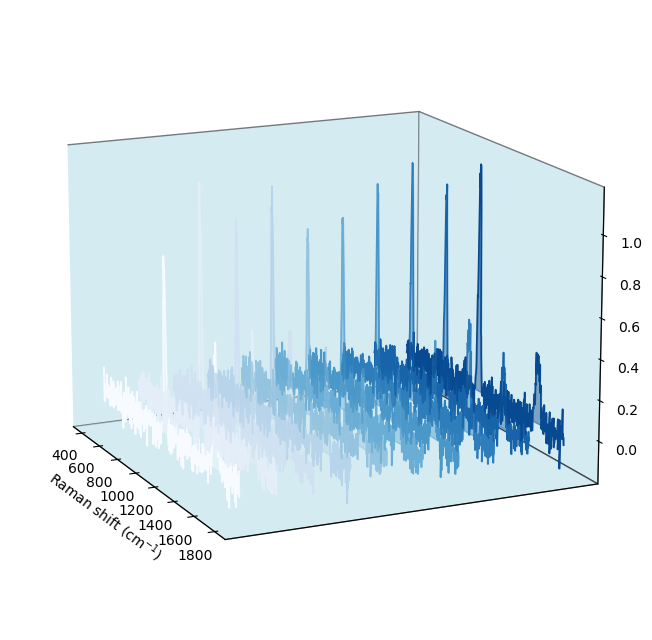

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D   # noqa: F401

# -------------------------------------------------
# 1. 构造 10 条模拟 SERS 光谱 (可替换成真实数据)
# -------------------------------------------------
raman_shift = np.linspace(400, 1800, 600)          # X 轴
n_spectra   = 10                                   # Y 轴（空间位置）
spectra     = np.empty((n_spectra, raman_shift.size))

# 每条光谱在 1070 和 1580 cm⁻¹ 附近有两个高斯峰，强度随机变化
for i in range(n_spectra):
    amp1, amp2 = np.random.uniform(800, 1200), np.random.uniform(300, 600)
    spectra[i] = (
        amp1 * np.exp(-((raman_shift - 1070) / 15) ** 2)
      + amp2 * np.exp(-((raman_shift - 1580) / 25) ** 2)
      + 50 * np.random.randn(raman_shift.size)
    )

# -------------------------------------------------
# 2. 3D 瀑布图
# -------------------------------------------------
fig = plt.figure(figsize=(8, 12))
ax  = fig.add_subplot(111, projection='3d')

# 选用蓝冷色渐变
cmap = plt.get_cmap('Blues')
colors = [cmap(i / n_spectra) for i in range(n_spectra)]

offset = 0          # 控制每条光谱的垂直间距
for i, intensity in enumerate(spectra):
    ax.plot(
        raman_shift,
        np.full_like(raman_shift, i),
        intensity + offset * i,
        color=colors[i],
        lw=1.2
    )
    # 下方填充，增强立体效果
    ax.add_collection3d(
        plt.fill_between(
            raman_shift,
            offset * i,
            intensity + offset * i,
            color=colors[i],
            alpha=0.25
        ),
        zs=i, zdir='y'
    )

# -------------------------------------------------
# 3. 美化
# -------------------------------------------------
ax.set_xlabel('Raman shift (cm$^{-1}$)')
# ax.set_ylabel('Sample index', labelpad=8)
ax.set_zlabel('Intensity (×10$^3$ a.u.)')
# ax.set_title('3D SERS Spectra (Blue-cold tone)', pad=15)
ax.view_init(elev=15, azim=-25)            # 视角可调
ax.grid(False)
ax.xaxis.pane.set_edgecolor('k')  # 让 x 轴平面边框显示
ax.yaxis.pane.set_edgecolor('k')  # 让 y 轴平面边框显示
ax.zaxis.pane.set_edgecolor('k') 

ax.xaxis.pane.fill = True
ax.yaxis.pane.fill = True
ax.zaxis.pane.fill = True
ax.xaxis.pane.set_facecolor('lightblue')
ax.yaxis.pane.set_facecolor('lightblue')
ax.zaxis.pane.set_facecolor('lightblue')

ax.set_yticks([])                                       # 去掉 Y 轴刻度
ticks_z = ax.get_zticks()
ax.set_zticklabels([f'{v*1e-3:.1f}' for v in ticks_z])  # Z 轴数值除以 1000

plt.tight_layout()
plt.savefig('3D_SERS_waterfall.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

In [124]:
data = np.load('/mnt/c/Users/ouyangkang/Desktop/decoupling_visualization_data.npz')

In [125]:
print(list(data.keys()))

['s_l', 's_a', 's_v', 'c_l', 'c_a', 'c_v', 'labels']


In [126]:
data['s_l'].shape

(686, 60)

In [127]:
for key in list(data.keys()):
    print(data[key].shape)

(686, 60)
(686, 60)
(686, 60)
(686, 60)
(686, 60)
(686, 60)
(686,)


In [128]:
np.unique(data['labels'])

array([-3., -2., -1.,  0.,  1.,  2.,  3.], dtype=float32)

In [129]:
X_list, y_list = [], []

for label, key in enumerate(list(data.keys())[:-1]):
    array = data[key]
    X_list.append(array)
    y_list.append(np.full(array.shape[0], label))

X = np.vstack(X_list)
y_ture = np.hstack(y_list)

In [380]:
for label, key in enumerate(list(data.keys())[:-1]):
    print([label, key])

[0, 's_l']
[1, 's_a']
[2, 's_v']
[3, 'c_l']
[4, 'c_a']
[5, 'c_v']


In [ ]:
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

In [309]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [310]:
X = StandardScaler().fit_transform(X)

In [336]:
X_pca = PCA(n_components=30).fit_transform(X)

In [312]:
X_2d  = TSNE(n_components=2, perplexity=50, random_state=42, learning_rate='auto', n_iter=2000, init='pca').fit_transform(X_pca)

/home/ouyangkang/software/miniconda3/envs/sc/lib/python3.11/site-packages/sklearn/manifold/_t_sne.py:1162: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


In [313]:
kmeans = KMeans(n_clusters=6, random_state=42)
cluster_labels = kmeans.fit_predict(X_2d) 

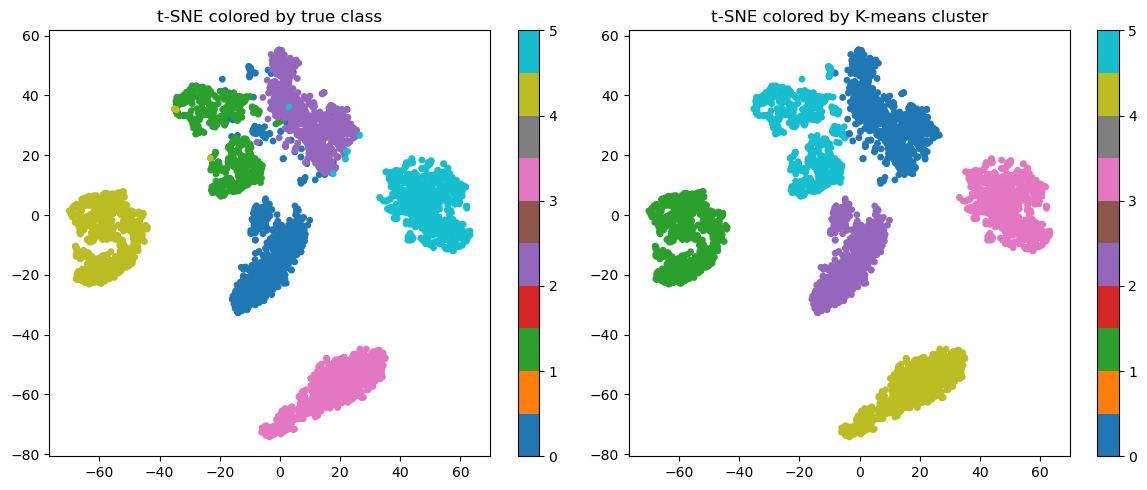

In [314]:
plt.figure(figsize=(12, 5))

# 左图：真实类别
plt.subplot(1, 2, 1)
scatter1 = plt.scatter(X_2d[:, 0], X_2d[:, 1],
                       c=y_ture, cmap='tab10', s=15)
plt.title('t-SNE colored by true class')
plt.colorbar(scatter1, ticks=range(6))

# 右图：聚类结果
plt.subplot(1, 2, 2)
scatter2 = plt.scatter(X_2d[:, 0], X_2d[:, 1],
                       c=cluster_labels, cmap='tab10', s=15)
plt.title('t-SNE colored by K-means cluster')
plt.colorbar(scatter2, ticks=range(6))

plt.tight_layout()
plt.show()

In [194]:
X_log = np.log(X_2d - np.min(X_2d) + 0.001)

In [196]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0, 1))
X_log = scaler.fit_transform(X_2d)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


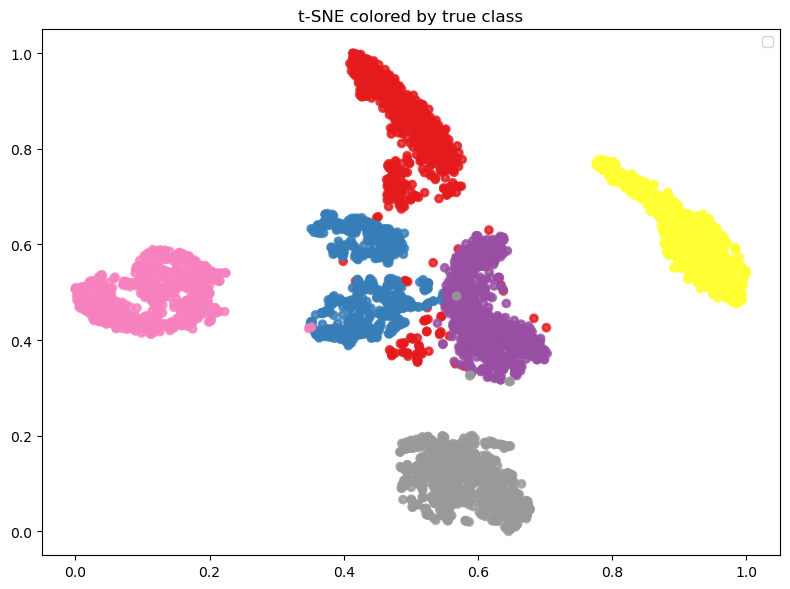

In [197]:
plt.figure(figsize=(8, 6))

scatter1 = plt.scatter(X_log[:, 0], X_log[:, 1],
                       c=y_ture, cmap='Set1', s=25, alpha=0.8, linewidths=2)
plt.title('t-SNE colored by true class')

plt.legend()
plt.tight_layout()
plt.show()

In [145]:
import umap

In [340]:
from sklearn.preprocessing import PowerTransformer

X_pt = PowerTransformer(method='yeo-johnson').fit_transform(X_pca)

In [363]:
X_2d = umap.UMAP(n_neighbors=12, min_dist=0.3, random_state=26, spread=1.5).fit_transform(X_pca)

/home/ouyangkang/software/miniconda3/envs/sc/lib/python3.11/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


In [364]:
kmeans = KMeans(n_clusters=6, random_state=42)
cluster_labels = kmeans.fit_predict(X_2d) 

In [381]:
for label, key in enumerate(list(data.keys())[:-1]):
    print([label, key])

[0, 's_l']
[1, 's_a']
[2, 's_v']
[3, 'c_l']
[4, 'c_a']
[5, 'c_v']


In [ ]:
text_mapping = {
    "0": "",
    "1": "",
    "2": "",
    "3": "",
    "4": "",
    "5": ""
}

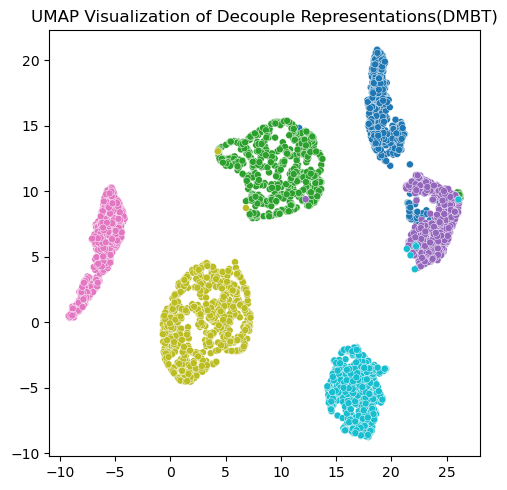

In [378]:
plt.figure(figsize=(5, 5))

scatter1 = plt.scatter(X_2d[:, 0], X_2d[:, 1],
                       c=y_ture, cmap='tab10', s=25, edgecolors='white', linewidths=0.3)
plt.title('UMAP Visualization of Decouple Representations(DMBT)')

plt.tight_layout()
plt.show()

/tmp/ipykernel_531/1194479998.py:42: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors = plt.cm.get_cmap('tab10', n_squares)


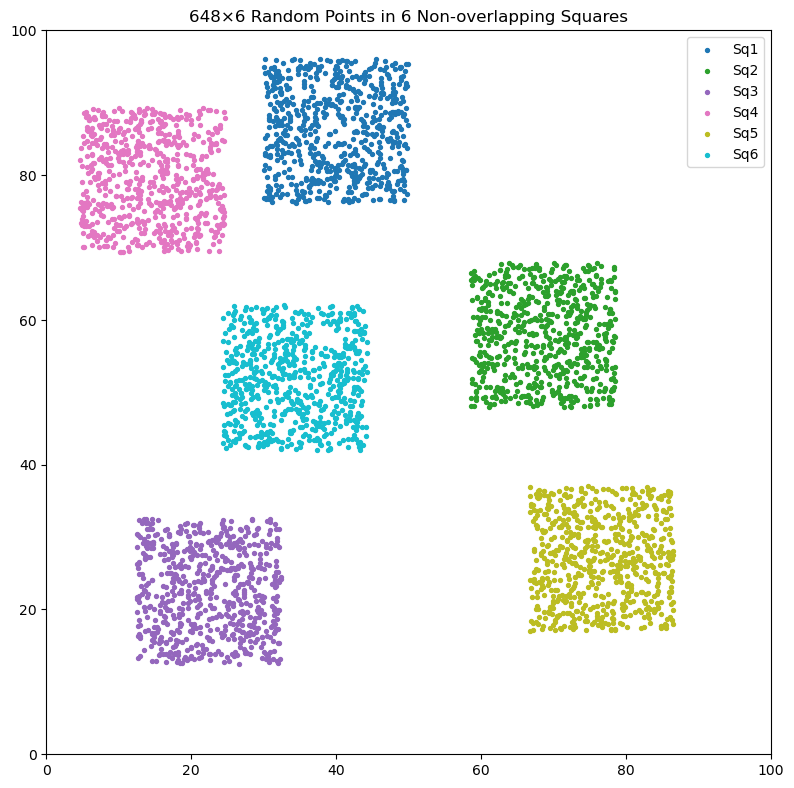

In [384]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# ---------- 参数 ----------
n_squares = 6           # 正方形个数
points_per_square = 648 # 每个正方形里的点数
square_side = 20.0       # 正方形边长（可改）
canvas = [0, 100, 0, 100] # 坐标系范围 x_min, x_max, y_min, y_max

np.random.seed(42)      # 固定随机种子，方便复现

# ---------- 1. 生成互不重叠的正方形 ----------
# 用“贪心+拒绝采样”思想：随机中心，直到不重叠
centers = []
side_half = square_side / 2.0

def overlap(c1, c2):
    return (abs(c1[0]-c2[0]) < square_side) and (abs(c1[1]-c2[1]) < square_side)

while len(centers) < n_squares:
    cx = np.random.uniform(canvas[0]+side_half, canvas[1]-side_half)
    cy = np.random.uniform(canvas[2]+side_half, canvas[3]-side_half)
    candidate = (cx, cy)
    if not any(overlap(candidate, c) for c in centers):
        centers.append(candidate)

# ---------- 2. 在每个正方形内部随机生成点 ----------
all_points = []
labels = []

for idx, (cx, cy) in enumerate(centers):
    xs = np.random.uniform(cx - side_half, cx + side_half, points_per_square)
    ys = np.random.uniform(cy - side_half, cy + side_half, points_per_square)
    all_points.append(np.column_stack([xs, ys]))
    labels.append(np.full(points_per_square, idx))

points = np.vstack(all_points)
labels = np.hstack(labels)

# ---------- 3. 绘制 ----------
colors = plt.cm.get_cmap('tab10', n_squares)
fig, ax = plt.subplots(figsize=(8, 8))

for idx, (cx, cy) in enumerate(centers):
    mask = labels == idx
    ax.scatter(points[mask, 0], points[mask, 1],
               s=8, color=colors(idx), label=f'Sq{idx+1}')

    '''
    # 画出正方形边框
    rect = Rectangle((cx - side_half, cy - side_half),
                     square_side, square_side,
                     linewidth=1.5, edgecolor='k', facecolor='none')
    ax.add_patch(rect)
    '''

ax.set_xlim(canvas[0], canvas[1])
ax.set_ylim(canvas[2], canvas[3])
ax.set_aspect('equal')
ax.legend()
ax.set_title('648×6 Random Points in 6 Non-overlapping Squares')
plt.tight_layout()
plt.show()

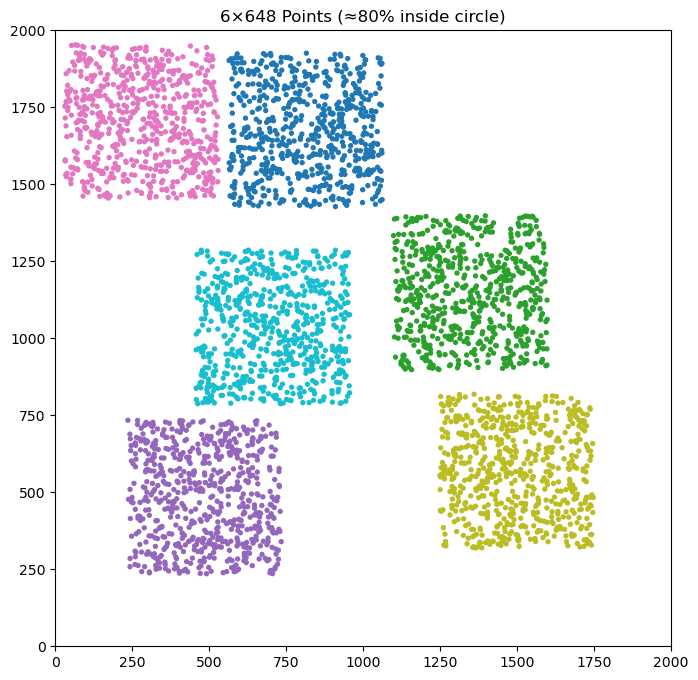

In [389]:
import numpy as np
import matplotlib.pyplot as plt

# ------------- 参数 -------------
n_squares   = 6
total_pts   = 648           # 每个 square 的总点数
ratio_in    = 0.80          # 内接圆内比例
square_side = 500.0
R           = square_side / 2.0   # 内接圆半径
canvas      = [0, 2000, 0, 2000]

np.random.seed(42)

# ------------- 工具函数 -------------
def square_center_to_corners(cx, cy):
    """返回正方形的四个角点，用于拒绝采样"""
    half = square_side / 2
    return cx - half, cx + half, cy - half, cy + half

def sample_in_circle(cx, cy, R, n):
    """在圆内均匀采样 n 个点"""
    theta = np.random.uniform(0, 2*np.pi, n)
    r = R * np.sqrt(np.random.uniform(0, 1, n))   # sqrt 保证均匀
    x = cx + r * np.cos(theta)
    y = cy + r * np.sin(theta)
    return np.column_stack((x, y))

def sample_outside_circle(cx, cy, R, n):
    """在正方形内、圆外拒绝采样 n 个点"""
    pts = []
    xmin, xmax, ymin, ymax = square_center_to_corners(cx, cy)
    while len(pts) < n:
        x = np.random.uniform(xmin, xmax)
        y = np.random.uniform(ymin, ymax)
        if (x - cx)**2 + (y - cy)**2 > R**2:
            pts.append((x, y))
    return np.array(pts)

# ------------- 1) 生成互不重叠的正方形中心 -------------
centers = []
half = square_side / 2
def overlap(c1, c2):
    return abs(c1[0]-c2[0])<square_side and abs(c1[1]-c2[1])<square_side

while len(centers) < n_squares:
    cx = np.random.uniform(canvas[0]+half, canvas[1]-half)
    cy = np.random.uniform(canvas[2]+half, canvas[3]-half)
    if not any(overlap((cx,cy),c) for c in centers):
        centers.append((cx,cy))

# ------------- 2) 生成点 -------------
pts_all, labels_all = [], []
for sq_idx, (cx, cy) in enumerate(centers):
    n_in  = int(np.round(ratio_in   * total_pts))
    n_out = total_pts - n_in

    pts_in  = sample_in_circle(cx, cy, R, n_in)
    pts_out = sample_outside_circle(cx, cy, R, n_out)

    pts = np.vstack((pts_in, pts_out))
    pts_all.append(pts)
    labels_all.append(np.full(total_pts, sq_idx))

points = np.vstack(pts_all)
labels = np.hstack(labels_all)

# ------------- 3) 绘图 -------------
plt.figure(figsize=(8,8))
plt.scatter(points[:,0], points[:,1], c=labels, cmap='tab10', s=8)
plt.xlim(canvas[0], canvas[1])
plt.ylim(canvas[2], canvas[3])
plt.gca().set_aspect('equal')
plt.title(f'{n_squares}×{total_pts} Points (≈{int(ratio_in*100)}% inside circle)')
plt.show()

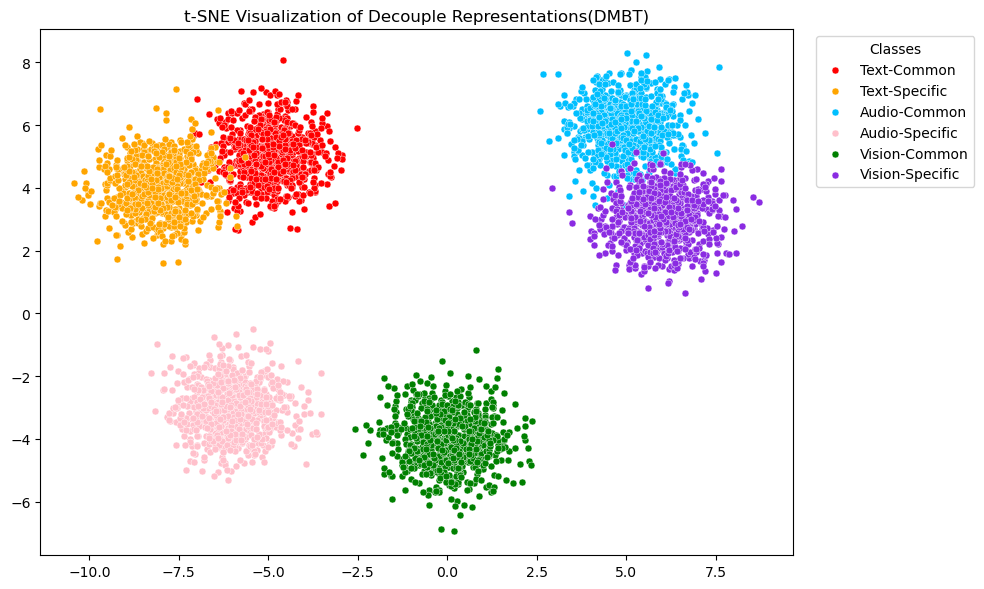

In [577]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score


colors = ['#FF0000', '#FFA500', '#00BFFF', '#FFC0CB', '#008000', '#8A2BE2']
labels = ['Text-Common', 'Text-Specific', 'Audio-Common',
          'Audio-Specific', 'Vision-Common', 'Vision-Specific']

# 1. 生成数据：6 个中心，2 维特征，共 1200 个样本
centers = np.array([[-5,  5],
                    [ -8, 4],
                    [ 5,  6],
                    [-6, -3],
                    [ 0, -4],
                    [ 6, 3]])
X, y_true = make_blobs(n_samples=800*6,
                       centers=centers,
                       cluster_std=0.8,
                       random_state=42)

# 2. 聚类
kmeans = KMeans(n_clusters=6, random_state=42)
y_pred = kmeans.fit_predict(X)

# 3. 可视化
fig, ax = plt.subplots(figsize=(10, 6))

# 左侧：真实标签
for k in range(6):
    mask = y_true == k
    ax.scatter(X[mask, 0], X[mask, 1],
               c=colors[k],
               s=25,
               edgecolors='white',
               linewidths=0.3,
               label=labels[k])
plt.title("t-SNE Visualization of Decouple Representations(DMBT)")
ax.legend(title='Classes', frameon=True, loc='upper right', bbox_to_anchor=(1.25, 1.0))
plt.tight_layout()
plt.savefig('/mnt/c/Users/ouyangkang/Desktop/result.png', format='png', dpi=150)
plt.show()

In [578]:
# 随机数种子保持一致
rng = np.random.RandomState(42)

# -------- 类别 0 → 横向椭圆 --------
mask0 = y_true == 0
X0 = X[mask0]
# 构造拉伸矩阵：x 放大 2.5 倍，y 不变
T0 = np.array([[2.5, 0],
               [0,   1]])
angle0 = np.radians(30)
R0 = np.array([[np.cos(angle0), -np.sin(angle0)],
               [np.sin(angle0),  np.cos(angle0)]])
X[mask0] = (X0 @ T0.T) @ R0.T

# -------- 类别 0 → 横向椭圆 --------
mask1 = y_true == 1
X1 = X[mask1]
# 构造拉伸矩阵：x 放大 2.5 倍，y 不变
T1 = np.array([[2.5, 0],
               [0,   1.6]])
angle1 = np.radians(-20)
R1 = np.array([[np.cos(angle1), -np.sin(angle1)],
               [np.sin(angle1),  np.cos(angle1)]])
X[mask1] = (X1 @ T1.T) @ R1.T

# 2
mask2 = y_true == 2
X2 = X[mask2]
# 构造拉伸矩阵：x 放大 2.5 倍，y 不变
T2 = np.array([[1, 0],
               [0, 1.8]])
angle2 = np.radians(50)
R2 = np.array([[np.cos(angle2), -np.sin(angle2)],
               [np.sin(angle2),  np.cos(angle2)]])
X[mask2] = (X2 @ T2.T) @ R2.T

# -------- 类别 3 → 竖向椭圆 --------
mask3 = y_true == 3
X3 = X[mask3]
# 构造拉伸矩阵：x 缩小 0.4 倍，y 放大 1.8 倍
T3 = np.array([[1.8, 0],
               [0,  1.8]])
angle3 = np.radians(70)
R3 = np.array([[np.cos(angle3), -np.sin(angle3)],
               [np.sin(angle3),  np.cos(angle3)]])
X[mask3] = (X3 @ T3.T) @ R3.T

# -------- 类别 5 → 竖向椭圆 --------
mask5 = y_true == 5
X5 = X[mask5]
# 构造拉伸矩阵：x 缩小 0.4 倍，y 放大 1.8 倍
T5 = np.array([[0.6, 0],
               [0,  2]])
X[mask5] = X5 @ T5.T

# 如果想让椭圆再旋转一定角度，用旋转矩阵即可：
# angle = np.radians(30)
# R = np.array([[np.cos(angle), -np.sin(angle)],
#               [np.sin(angle),  np.cos(angle)]])
# X[mask0] = (X0 @ T0.T) @ R.T

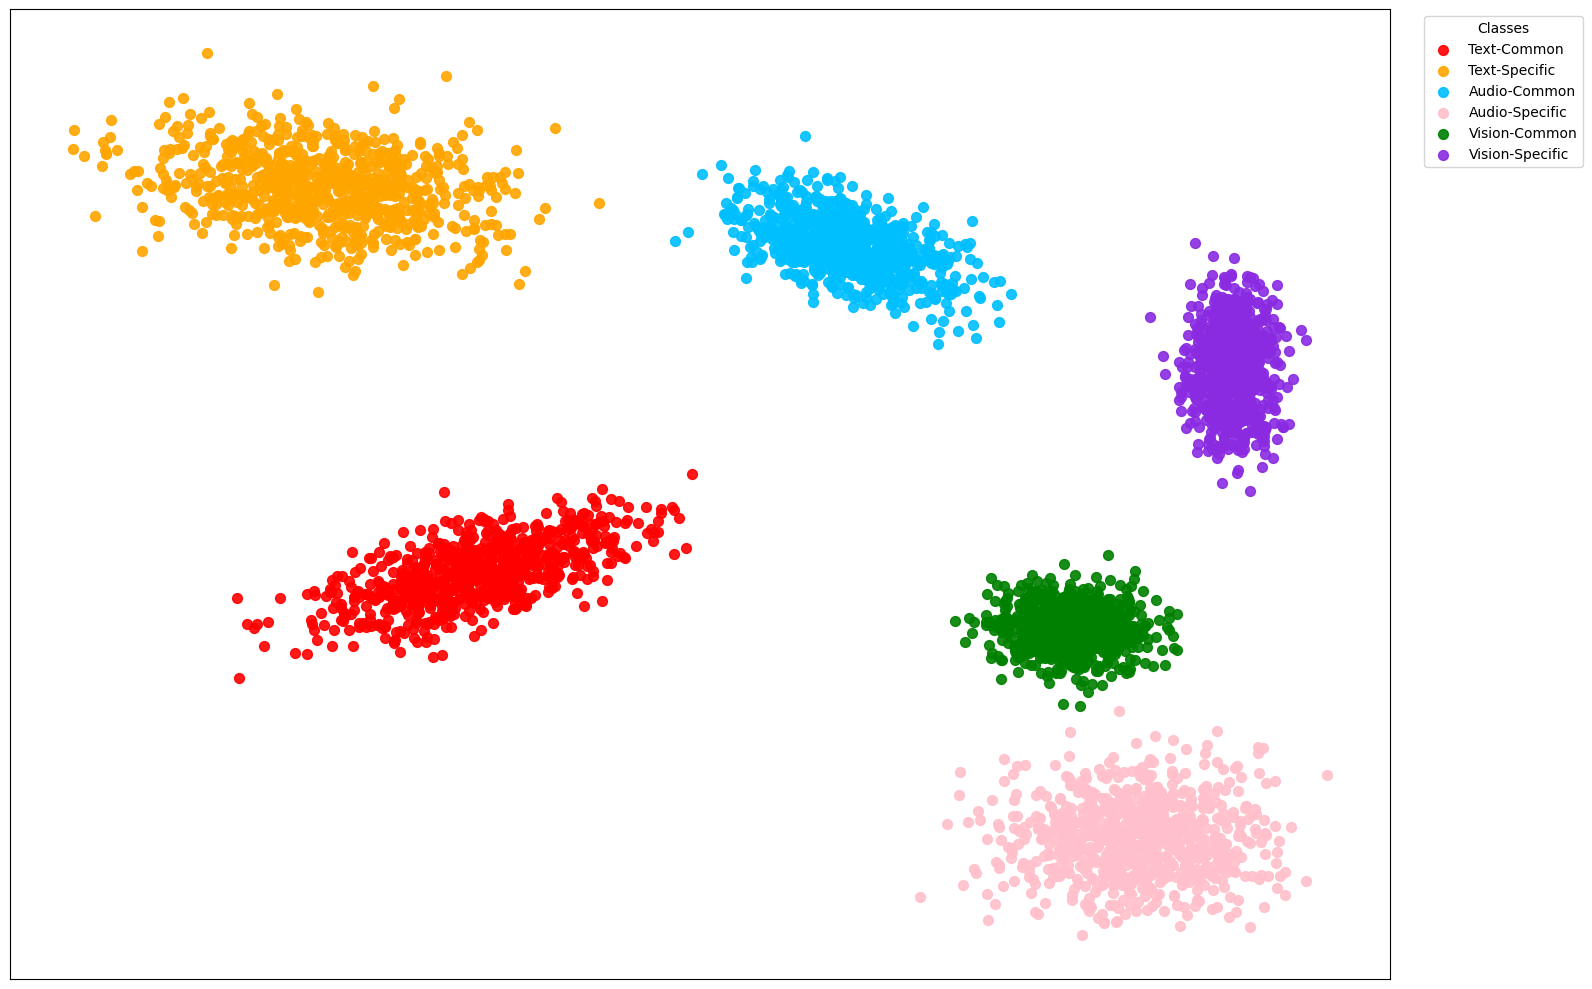

In [591]:
fig, ax = plt.subplots(figsize=(16, 10))

# 左侧：真实标签
for k in range(6):
    mask = y_true == k
    ax.scatter(X[mask, 0], X[mask, 1],
               c=colors[k],
               s=50, alpha=0.9,
               label=labels[k])
#plt.title("t-SNE Visualization of Decouple Representations(DMBT)", fontsize=14)
ax.legend(title='Classes', frameon=True, loc='upper left', bbox_to_anchor=(1.02, 1.0))
ax.set_xticks([])
ax.set_yticks([])
plt.tight_layout()
plt.savefig('/mnt/c/Users/ouyangkang/Desktop/result.png', format='png', dpi=300)
plt.show()